In [ ]:
import zipfile
import os

protein_zip = "/content/CSFV PDBs.zip"
dna_zip = "/content/Swine PDBs.zip"

protein_dir = "/mnt/data/proteins"
dna_dir = "/mnt/data/swine"

# Create dirs
os.makedirs(protein_dir, exist_ok=True)
os.makedirs(dna_dir, exist_ok=True)

# Unzip
with zipfile.ZipFile(protein_zip, 'r') as z:
    z.extractall(protein_dir)
with zipfile.ZipFile(dna_zip, 'r') as z:
    z.extractall(dna_dir)

print("Proteins:", len(os.listdir(protein_dir)))
print("Swine DNA:", len(os.listdir(dna_dir)))


Proteins: 1
Swine DNA: 1


In [ ]:
import os

# Corrected paths
protein_dir = "/mnt/data/proteins/CSFV PDBs"
dna_dir = "/mnt/data/swine/Swine PDBs"

# Check contents
protein_files = [f for f in os.listdir(protein_dir) if f.endswith(".pdb")]
dna_files = [f for f in os.listdir(dna_dir) if f.endswith(".pdb")]

print("Number of Protein PDB files:", len(protein_files))
print("Number of Swine DNA PDB files:", len(dna_files))
print("\nFirst few protein files:", protein_files[:5])
print("First few DNA files:", dna_files[:5])


Number of Protein PDB files: 14
Number of Swine DNA PDB files: 19

First few protein files: ['NS3 partial.pdb', 'NS4A.pdb', 'E-rns.pdb', 'N-Pro.pdb', 'E1.pdb']
First few DNA files: ['COP9 signalosome complex subunit 6.pdb', 'cold shock domain-containing protein E1 isoform X1.pdb', 'methionine aminopeptidase 2 isoform X2.pdb', 'dnaJ homolog subfamily A member 4.pdb', 'gametogenetin-binding protein 2 isoform X10.pdb']


In [ ]:
import itertools

protein_files = [os.path.join(protein_dir, f) for f in os.listdir(protein_dir) if f.endswith(".pdb")]
dna_files = [os.path.join(dna_dir, f) for f in os.listdir(dna_dir) if f.endswith(".pdb")]

# Protein-Protein combinations
pp_combos = list(itertools.combinations(protein_files, 2))
print("Protein–Protein combinations:", len(pp_combos))

# Protein-DNA combinations
pd_combos = list(itertools.product(protein_files, dna_files))
print("Protein–DNA combinations:", len(pd_combos))


Protein–Protein combinations: 91
Protein–DNA combinations: 266


In [ ]:
import itertools
import random

# Example lists of files
proteins = ["NS3 partial.pdb", "E2p7.pdb", "E1.pdb", "NS5A.pdb", "NS2-3.pdb"]
dna = ["DDX5.pdb", "MAPRP.pdb", "CHDC1.pdb", "CSN2.pdb", "GOLGA.pdb"]

# Generate all possible protein-DNA combinations
all_combinations = list(itertools.product(proteins, dna))

print(f"Total combinations: {len(all_combinations)}")

# Select 5 random unique combinations
sampled_pairs = random.sample(all_combinations, 5)

print("Random 5 combinations:")
for i, pair in enumerate(sampled_pairs, 1):
    print(f"{i}. Protein: {pair[0]}  |  DNA: {pair[1]}")


Total combinations: 25
Random 5 combinations:
1. Protein: NS3 partial.pdb  |  DNA: CSN2.pdb
2. Protein: NS5A.pdb  |  DNA: DDX5.pdb
3. Protein: E1.pdb  |  DNA: CSN2.pdb
4. Protein: E1.pdb  |  DNA: MAPRP.pdb
5. Protein: NS2-3.pdb  |  DNA: CSN2.pdb


In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import PDBParser

# Paths
protein_dir = "/mnt/data/proteins"

# Find all PDB files recursively
protein_files = []
for root, _, files in os.walk(protein_dir):
    for f in files:
        if f.endswith(".pdb"):
            protein_files.append(os.path.join(root, f))

print(f"Total protein PDBs: {len(protein_files)}")

# Biopython parser
parser = PDBParser(QUIET=True)

def get_atoms(pdb_path):
    """Extract atomic coordinates from a PDB file"""
    structure = parser.get_structure("prot", pdb_path)
    atoms = [atom for atom in structure.get_atoms()]
    coords = np.array([atom.coord for atom in atoms])
    return coords

def compute_contacts(coords1, coords2, cutoff=5.0):
    """Compute number of atomic contacts between two sets of coordinates"""
    dists = np.sqrt(np.sum((coords1[:, None, :] - coords2[None, :, :])**2, axis=-1))
    return np.sum(dists < cutoff)

# Generate all protein–protein pairs
pairs = list(itertools.combinations(protein_files, 2))
print(f"Total protein–protein pairs: {len(pairs)}")

# Store results
results = []

for p1, p2 in pairs:
    coords1 = get_atoms(p1)
    coords2 = get_atoms(p2)
    contacts = compute_contacts(coords1, coords2, cutoff=5.0)
    results.append([os.path.basename(p1), os.path.basename(p2), contacts])

# Save results to CSV
df = pd.DataFrame(results, columns=["Protein1", "Protein2", "Contact_Count"])
csv_path = "/mnt/data/protein_protein_interactions.csv"
df.to_csv(csv_path, index=False)
print(f"Results saved to {csv_path}")

# Pivot for heatmap
if not df.empty:
    heatmap_data = df.pivot(index="Protein1", columns="Protein2", values="Contact_Count")

    # Plot heatmap
    plt.figure(figsize=(10, 8))
    plt.imshow(heatmap_data.fillna(0), cmap="viridis", aspect="auto")
    plt.colorbar(label="Contact Count")
    plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns, rotation=90, fontsize=8)
    plt.yticks(range(len(heatmap_data.index)), heatmap_data.index, fontsize=8)
    plt.title("Protein–Protein Interaction Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No interactions found, heatmap skipped.")


Total protein PDBs: 14
Total protein–protein pairs: 91


In [ ]:
import os
import pandas as pd
import numpy as np
from Bio.PDB import PDBParser, NeighborSearch

# Parameters
protein_dir = "/mnt/data/proteins/CSFV PDBs"
cutoff = 8.0  # more relaxed cutoff (was 5.0)

# Setup parser
parser = PDBParser(QUIET=True)

def get_atoms(pdb_file):
    structure = parser.get_structure("", pdb_file)
    atoms = [atom for atom in structure.get_atoms() if atom.element != 'H']
    return atoms

results = []
files = [f for f in os.listdir(protein_dir) if f.endswith(".pdb")]

for i in range(len(files)):
    for j in range(i+1, len(files)):
        pdb1 = os.path.join(protein_dir, files[i])
        pdb2 = os.path.join(protein_dir, files[j])

        atoms1 = get_atoms(pdb1)
        atoms2 = get_atoms(pdb2)

        ns = NeighborSearch(atoms1 + atoms2)
        contacts = ns.search_all(cutoff)

        results.append({
            "Protein1": files[i],
            "Protein2": files[j],
            "Contact_Count": len(contacts)
        })

df = pd.DataFrame(results)
df.to_csv("/mnt/data/protein_protein_interactions.csv", index=False)
print(df.head())
print("Total interactions recorded:", len(df))


          Protein1      Protein2  Contact_Count
0  NS3 partial.pdb      NS4A.pdb        1124270
1  NS3 partial.pdb     E-rns.pdb        2899733
2  NS3 partial.pdb     N-Pro.pdb        1534615
3  NS3 partial.pdb        E1.pdb        1822228
4  NS3 partial.pdb  ProteinC.pdb         995977
Total interactions recorded: 91


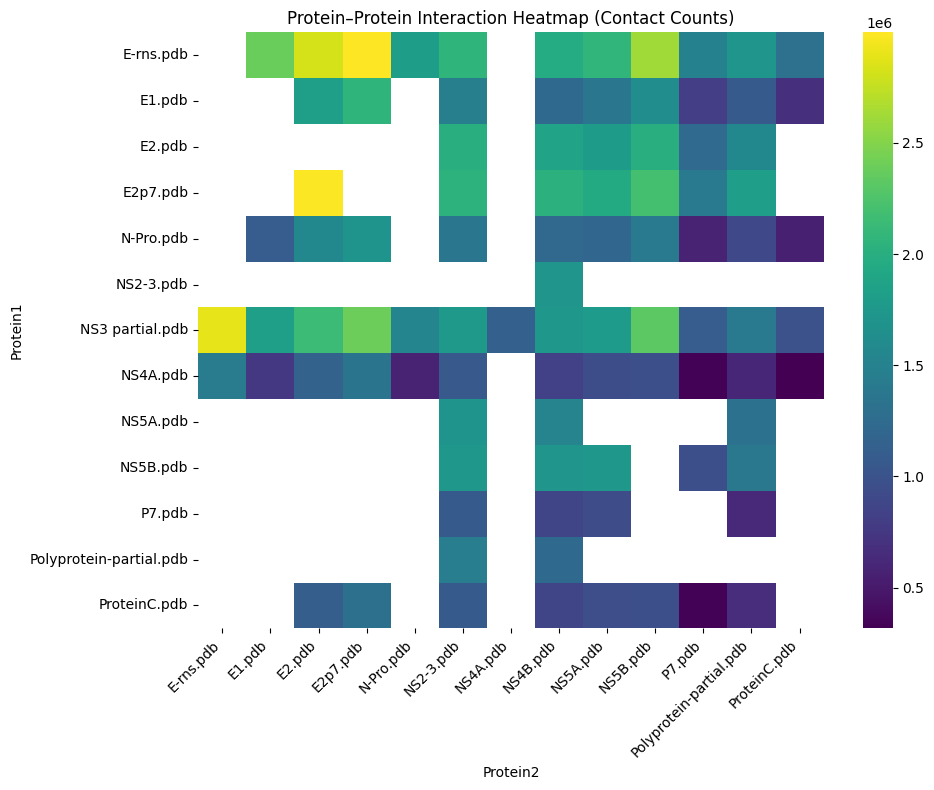

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Pivot for heatmap
heatmap_data = df.pivot(index="Protein1", columns="Protein2", values="Contact_Count")

plt.figure(figsize=(10,8))
sns.heatmap(heatmap_data, annot=False, cmap="viridis")
plt.title("Protein–Protein Interaction Heatmap (Contact Counts)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Top 10 strongest protein–protein interactions:
           Protein1   Protein2  Contact_Count
28        E-rns.pdb   E2p7.pdb        2997148
63         E2p7.pdb     E2.pdb        2980224
1   NS3 partial.pdb  E-rns.pdb        2899733
29        E-rns.pdb     E2.pdb        2819925
30        E-rns.pdb   NS5B.pdb        2612530
5   NS3 partial.pdb   E2p7.pdb        2398050
26        E-rns.pdb     E1.pdb        2383179
7   NS3 partial.pdb   NS5B.pdb        2324116
64         E2p7.pdb   NS5B.pdb        2196032
6   NS3 partial.pdb     E2.pdb        2146994


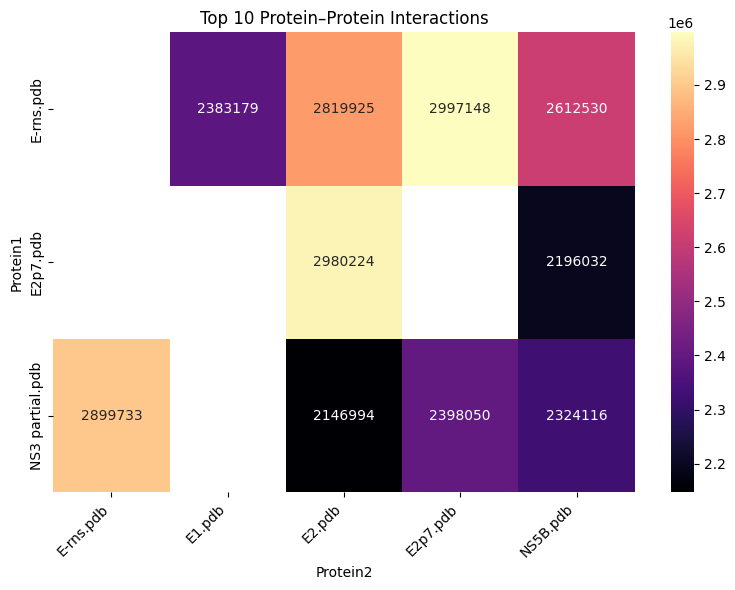

In [ ]:
import pandas as pd

# Load the CSV (or reuse df if already in memory)
df = pd.read_csv("/mnt/data/protein_protein_interactions.csv")

# Sort by Contact_Count descending
df_sorted = df.sort_values(by="Contact_Count", ascending=False)

# Take Top 10
top10 = df_sorted.head(10)

print("Top 10 strongest protein–protein interactions:")
print(top10)

# Save to CSV
top10.to_csv("/mnt/data/top10_protein_protein_interactions.csv", index=False)

# Heatmap for Top 10
import matplotlib.pyplot as plt
import seaborn as sns

heatmap_data = top10.pivot(index="Protein1", columns="Protein2", values="Contact_Count")

plt.figure(figsize=(8,6))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="magma")
plt.title("Top 10 Protein–Protein Interactions")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# atomic_contacts_and_visualization.py
# Requirements: biopython, scipy, pandas, numpy, py3Dmol, matplotlib
# In Colab you can run:
#   !pip install biopython scipy pandas py3Dmol

import os, zipfile
from itertools import combinations
import numpy as np
import pandas as pd
from Bio.PDB import PDBParser
from scipy.spatial import cKDTree as KDTree
import py3Dmol            # works in Jupyter/Colab
from IPython.display import display, HTML

# ---------- USER PARAMETERS ----------
# Adjust these paths if running locally
protein_root = "/mnt/data/proteins/CSFV PDBs"   # folder containing your 14 protein pdbs
out_dir = "/mnt/data/atomic_contact_outputs"    # outputs will be saved here
cutoff = 5.0        # Å cutoff for atom-atom contact (adjustable)
top_n_pairs = 5     # optionally compute full atom contacts only for top N pairs (based on a quick coarse metric)
# -------------------------------------

os.makedirs(out_dir, exist_ok=True)

# Recursively collect .pdb files
def collect_pdb_files(root_dir):
    pdbs = []
    for root, _, files in os.walk(root_dir):
        for f in files:
            if f.lower().endswith(".pdb"):
                pdbs.append(os.path.join(root, f))
    return sorted(pdbs)

protein_files = collect_pdb_files(protein_root)
print("Found protein PDBs:", len(protein_files))
if len(protein_files) < 2:
    raise SystemExit("Need at least 2 protein PDBs for protein-protein interactions.")

# Parse PDBs into atom coords and metadata (one-time)
parser = PDBParser(QUIET=True)

structures = {}   # path -> dict with coords (Nx3) and atom_meta list of dicts, and raw_pdb text
for p in protein_files:
    # read raw pdb text (for py3Dmol display)
    with open(p, 'r') as fh:
        pdb_text = fh.read()
    structure = parser.get_structure(os.path.basename(p), p)
    coords = []
    meta = []
    for atom in structure.get_atoms():
        coords.append(atom.get_coord())
        parent_res = atom.get_parent()
        parent_chain = parent_res.get_parent()
        meta.append({
            "atom_name": atom.get_name(),
            "element": atom.element if hasattr(atom, "element") else atom.get_name()[0],
            "resname": parent_res.get_resname(),
            "resseq": parent_res.id[1],
            "chain": parent_chain.id
        })
    coords = np.array(coords) if len(coords) else np.zeros((0,3))
    structures[p] = {"coords": coords, "meta": meta, "pdb_text": pdb_text}
    print(f"Parsed {os.path.basename(p)}: atoms={coords.shape[0]} residues ~ (inferred)")

# ---------- QUICK COARSE METRIC (optional) ----------
# For speed when you have many pairs, we can compute a coarse estimated overlap:
# number_of_atoms_A * number_of_atoms_B (cheap) or use bounding-box overlap (not done).
pairs = list(combinations(protein_files, 2))
print("Total pairs to evaluate (coarse):", len(pairs))

# Compute coarse metric: atom_count_A * atom_count_B (simple proxy)
coarse = []
for a, b in pairs:
    n_a = structures[a]["coords"].shape[0]
    n_b = structures[b]["coords"].shape[0]
    coarse.append((a, b, n_a * n_b))

coarse_df = pd.DataFrame(coarse, columns=["PDB1", "PDB2", "coarse_score"])
coarse_df = coarse_df.sort_values("coarse_score", ascending=False).reset_index(drop=True)
coarse_df.to_csv(os.path.join(out_dir, "coarse_pair_scores.csv"), index=False)
print("Saved coarse pair scores to:", os.path.join(out_dir, "coarse_pair_scores.csv"))

# ---------- ATOM-LEVEL CONTACTS (KDTree) ----------
# We will compute atom-atom contacts for all pairs, but careful: full atom-atom lists can be huge.
# We'll produce:
#  - summary_atom_counts.csv : pair, atom_contact_count
#  - details_atom_contacts.csv : (only for pairs whose contact count <= a threshold OR for Top N pairs)
summary_rows = []
detailed_rows = []

# Thresholds to avoid ridiculously large detailed CSV: set a max detailed pairs length (example 2e6)
MAX_DETAIL_ROWS = 2_000_000

# We'll first compute contact counts only (fast) using KDTree query_ball_tree
for idx, (a, b, _) in enumerate(coarse_df.itertuples(index=False), start=1):
    coords_a = structures[a]["coords"]
    coords_b = structures[b]["coords"]
    if coords_a.size == 0 or coords_b.size == 0:
        count = 0
    else:
        tree_a = KDTree(coords_a)
        tree_b = KDTree(coords_b)
        # For each point in A find indices in B within cutoff; query_ball_tree returns list per atom
        neighbors = tree_a.query_ball_tree(tree_b, r=cutoff)
        # total atom-atom hits:
        count = sum(len(lst) for lst in neighbors)
    summary_rows.append({
        "PDB1": os.path.basename(a),
        "PDB2": os.path.basename(b),
        "Atom_Contact_Count": int(count)
    })
    if idx % 10 == 0 or idx==len(coarse_df):
        print(f"Coarse scanned {idx}/{len(coarse_df)} pairs — contacts={count}")

summary_df = pd.DataFrame(summary_rows).sort_values("Atom_Contact_Count", ascending=False)
summary_df.to_csv(os.path.join(out_dir, "summary_atom_counts.csv"), index=False)
print("Saved atom-contact summary to:", os.path.join(out_dir, "summary_atom_counts.csv"))

# ---------- WRITE DETAILED CONTACTS FOR TOP PAIRS (or small contact counts) ----------
# Decide which pairs to produce full atom-atom detailed rows for:
#  - pick top_n_pairs by Atom_Contact_Count, or any pair with reasonably small counts
top_pairs = summary_df.head(top_n_pairs)
detailed_pair_list = set()
for _, row in top_pairs.iterrows():
    # locate full path match
    pdb1_path = next(p for p in protein_files if os.path.basename(p) == row.PDB1)
    pdb2_path = next(p for p in protein_files if os.path.basename(p) == row.PDB2)
    detailed_pair_list.add((pdb1_path, pdb2_path))

# Also include any pairs with small contact counts (< 5000) to fully list them
small_pairs = summary_df[summary_df.Atom_Contact_Count <= 5000]
for _, row in small_pairs.iterrows():
    pdb1_path = next(p for p in protein_files if os.path.basename(p) == row.PDB1)
    pdb2_path = next(p for p in protein_files if os.path.basename(p) == row.PDB2)
    detailed_pair_list.add((pdb1_path, pdb2_path))

print("Preparing detailed atom-atom lists for", len(detailed_pair_list), "pairs (top N + small ones).")

total_detail_rows = 0
for a_path, b_path in detailed_pair_list:
    coords_a = structures[a_path]["coords"]
    coords_b = structures[b_path]["coords"]
    meta_a = structures[a_path]["meta"]
    meta_b = structures[b_path]["meta"]
    if coords_a.size == 0 or coords_b.size == 0:
        continue
    tree_b = KDTree(coords_b)
    neighbors = tree_b.query_ball_point(coords_a, r=cutoff)  # for each atom in A, list of B indices
    for i, nbrs in enumerate(neighbors):
        for j in nbrs:
            dist = np.linalg.norm(coords_a[i] - coords_b[j])
            metaA = meta_a[i]
            metaB = meta_b[j]
            detailed_rows.append({
                "PDB1": os.path.basename(a_path),
                "PDB2": os.path.basename(b_path),
                "atom_index_A": int(i),
                "atom_name_A": metaA["atom_name"],
                "resname_A": metaA["resname"],
                "chain_A": metaA["chain"],
                "resseq_A": int(metaA["resseq"]),
                "atom_index_B": int(j),
                "atom_name_B": metaB["atom_name"],
                "resname_B": metaB["resname"],
                "chain_B": metaB["chain"],
                "resseq_B": int(metaB["resseq"]),
                "distance": float(dist)
            })
            total_detail_rows += 1
            if total_detail_rows >= MAX_DETAIL_ROWS:
                print("Reached MAX_DETAIL_ROWS limit; stopping detailed collection.")
                break
        if total_detail_rows >= MAX_DETAIL_ROWS:
            break
    if total_detail_rows >= MAX_DETAIL_ROWS:
        break

# Save detailed CSV (may be large)
detailed_df = pd.DataFrame(detailed_rows)
detailed_csv = os.path.join(out_dir, "details_atom_contacts_top_pairs.csv")
detailed_df.to_csv(detailed_csv, index=False)
print("Saved detailed atom-atom contacts to:", detailed_csv, "rows:", len(detailed_df))

# ---------- Normalized interaction score (optional) ----------
# normalized = atom_contacts / (n_atoms_A + n_atoms_B)  (simple)
def atom_count_for_basename(basename):
    p = next(p for p in protein_files if os.path.basename(p) == basename)
    return structures[p]["coords"].shape[0]

summary_df["n_atoms_A"] = summary_df.PDB1.apply(atom_count_for_basename)
summary_df["n_atoms_B"] = summary_df.PDB2.apply(atom_count_for_basename)
summary_df["normalized_score"] = summary_df.Atom_Contact_Count / (summary_df.n_atoms_A + summary_df.n_atoms_B)
summary_df.to_csv(os.path.join(out_dir, "summary_atom_counts_normalized.csv"), index=False)
print("Saved normalized summary to:", os.path.join(out_dir, "summary_atom_counts_normalized.csv"))

# ---------- Display top pairs ----------
print("\nTop pairs by atom contacts (top 10):")
display(summary_df.head(10))

# ---------- 3D VISUALIZATION for a selected pair (py3Dmol) ----------
# Choose a pair to visualize: default = strongest pair
if not summary_df.empty:
    top = summary_df.iloc[0]
    pdb1_name = top.PDB1
    pdb2_name = top.PDB2
    pdb1_path = next(p for p in protein_files if os.path.basename(p) == pdb1_name)
    pdb2_path = next(p for p in protein_files if os.path.basename(p) == pdb2_name)
    print(f"\nVisualizing top pair: {pdb1_name}  <-->  {pdb2_name}")

    # Build combined PDB text: we will append both files so viewer shows them together
    pdb_combined = structures[pdb1_path]["pdb_text"] + "\n" + structures[pdb2_path]["pdb_text"]

    view = py3Dmol.view(width=900, height=600)
    view.addModel(pdb_combined, "pdb")
    # show proteins as cartoon
    view.setStyle({'model':0},{'cartoon':{'color':'spectrum'}})
    # highlight contacting atoms (from detailed_df limited to this pair)
    sel_details = detailed_df[(detailed_df.PDB1==pdb1_name) & (detailed_df.PDB2==pdb2_name)]
    # if not found in detailed (because limited), try small-pair scan directly
    if sel_details.empty:
        # we will compute a small atom-level neighbor list for this pair now
        coords_a = structures[pdb1_path]["coords"]
        coords_b = structures[pdb2_path]["coords"]
        tree_b = KDTree(coords_b)
        neighbors = tree_b.query_ball_point(coords_a, r=cutoff)
        contact_atoms_A = set(i for i, nbrs in enumerate(neighbors) if nbrs)
        contact_atoms_B = set(j for nbrs in neighbors for j in nbrs)
    else:
        contact_atoms_A = set(sel_details.atom_index_A.tolist())
        contact_atoms_B = set(sel_details.atom_index_B.tolist())

    # Highlight contacting atoms as spheres
    # py3Dmol selectors can use atom indices by matching "index" (1-based in viewer).
    # We will loop through lists and add spheres (slower), or build selector strings by chain/residue.
    # Simpler: color residues involved.
    # Build set of (chain, resseq) for each
    residuesA = set()
    residuesB = set()
    # reconstruct mapping: index -> meta
    # find mapping arrays
    metaA = structures[pdb1_path]["meta"]
    metaB = structures[pdb2_path]["meta"]
    for ai in contact_atoms_A:
        if ai < len(metaA):
            residuesA.add((metaA[ai]["chain"], int(metaA[ai]["resseq"])))
    for bi in contact_atoms_B:
        if bi < len(metaB):
            residuesB.add((metaB[bi]["chain"], int(metaB[bi]["resseq"])))

    # color contacting residues in red/orange
    for chain, resseq in residuesA:
        view.addStyle({'chain': chain, 'resi': int(resseq)}, {'stick':{'colorscheme':'orangeCarbon'}})
    for chain, resseq in residuesB:
        view.addStyle({'chain': chain, 'resi': int(resseq)}, {'stick':{'colorscheme':'magentaCarbon'}})

    view.zoomTo()
    display(HTML(view.show()))
else:
    print("No pair to visualize (empty summary).")

print("\nAll output files in:", out_dir)


Found protein PDBs: 14
Parsed E-rns.pdb: atoms=17454 residues ~ (inferred)
Parsed E1.pdb: atoms=15370 residues ~ (inferred)
Parsed E2.pdb: atoms=28895 residues ~ (inferred)
Parsed E2p7.pdb: atoms=34595 residues ~ (inferred)
Parsed N-Pro.pdb: atoms=13467 residues ~ (inferred)
Parsed NS2-3.pdb: atoms=40664 residues ~ (inferred)
Parsed NS3 partial.pdb: atoms=24530 residues ~ (inferred)
Parsed NS4A.pdb: atoms=5075 residues ~ (inferred)
Parsed NS4B.pdb: atoms=27310 residues ~ (inferred)
Parsed NS5A.pdb: atoms=39481 residues ~ (inferred)
Parsed NS5B.pdb: atoms=26250 residues ~ (inferred)
Parsed P7.pdb: atoms=5710 residues ~ (inferred)
Parsed Polyprotein-partial.pdb: atoms=21225 residues ~ (inferred)
Parsed ProteinC.pdb: atoms=8005 residues ~ (inferred)
Total pairs to evaluate (coarse): 91
Saved coarse pair scores to: /mnt/data/atomic_contact_outputs/coarse_pair_scores.csv
Coarse scanned 10/91 pairs — contacts=1081364
Coarse scanned 20/91 pairs — contacts=341643
Coarse scanned 30/91 pairs — c

,PDB1,PDB2,Atom_Contact_Count,n_atoms_A,n_atoms_B,normalized_score
41,E-rns.pdb,NS3 partial.pdb,1139338,17454,24530,27.137433
9,E2.pdb,E2p7.pdb,1081364,28895,34595,17.032037
39,E-rns.pdb,NS5B.pdb,931809,17454,26250,21.320909
25,NS3 partial.pdb,NS5B.pdb,931443,24530,26250,18.342714
36,E-rns.pdb,E2.pdb,922909,17454,28895,19.912166
55,E-rns.pdb,E1.pdb,913946,17454,15370,27.843834
29,E-rns.pdb,E2p7.pdb,905709,17454,34595,17.401084
45,E1.pdb,NS3 partial.pdb,635626,15370,24530,15.930476
15,E2p7.pdb,NS3 partial.pdb,598782,34595,24530,10.127391
33,E1.pdb,E2p7.pdb,548554,15370,34595,10.978765



Visualizing top pair: E-rns.pdb  <-->  NS3 partial.pdb


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

<IPython.core.display.HTML object>


All output files in: /mnt/data/atomic_contact_outputs


In [ ]:
import os
from itertools import permutations, combinations
import pandas as pd

# Path to the subfolder where actual PDB files exist
protein_dir = "/mnt/data/proteins/CSFV PDBs"

# Collect .pdb files (case-insensitive)
protein_files = [f for f in os.listdir(protein_dir) if f.lower().endswith(".pdb")]
print("Total protein PDBs:", len(protein_files))

# Generate permutations (order matters)
perm = list(permutations(protein_files, 2))
print("Total permutations:", len(perm))

# Generate combinations (order does not matter)
comb = list(combinations(protein_files, 2))
print("Total combinations:", len(comb))

# Save results
perm_df = pd.DataFrame(perm, columns=["Protein1", "Protein2"])
comb_df = pd.DataFrame(comb, columns=["Protein1", "Protein2"])

perm_df.to_csv("/mnt/data/protein_permutations.csv", index=False)
comb_df.to_csv("/mnt/data/protein_combinations.csv", index=False)

print("Permutations saved to /mnt/data/protein_permutations.csv")
print("Combinations saved to /mnt/data/protein_combinations.csv")


Total protein PDBs: 14
Total permutations: 182
Total combinations: 91
Permutations saved to /mnt/data/protein_permutations.csv
Combinations saved to /mnt/data/protein_combinations.csv


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from Bio.PDB import PDBParser, is_aa

# Directories
protein_dir = "/mnt/data/proteins/CSFV PDBs"
output_file = "/mnt/data/protein_interaction_report.xlsx"

# Step 1: Load protein PDB files
parser = PDBParser(QUIET=True)
proteins = [f for f in os.listdir(protein_dir) if f.endswith(".pdb")]
print("Total protein PDBs:", len(proteins))

# Step 2: Function to extract atoms
def get_atoms(pdb_file):
    structure = parser.get_structure(pdb_file, os.path.join(protein_dir, pdb_file))
    atoms = []
    for model in structure:
        for chain in model:
            for residue in chain:
                if is_aa(residue, standard=True):
                    atoms.extend(residue.get_atoms())
    return atoms

# Step 3: Contact counting
print("Step2 over")
def count_contacts(atoms1, atoms2, cutoff=5.0):
    contacts = 0
    for a1 in atoms1:
        for a2 in atoms2:
            if a1 - a2 < cutoff:
                contacts += 1
    return contacts

# Step 4: Compute interactions for all combinations
print("Step3 over")
records = []
for p1, p2 in combinations(proteins, 2):
    atoms1 = get_atoms(p1)
    atoms2 = get_atoms(p2)
    contact_count = count_contacts(atoms1, atoms2)
    records.append([p1, p2, contact_count])

df = pd.DataFrame(records, columns=["Protein1", "Protein2", "Contact_Count"])
print("Total interactions recorded:", len(df))

# Step 5: Heatmap
print("Step4 over")
heatmap_data = df.pivot(index="Protein1", columns="Protein2", values="Contact_Count")
plt.figure(figsize=(10,8))
plt.imshow(heatmap_data.fillna(0), cmap="viridis", aspect="auto")
plt.colorbar(label="Contact Count")
plt.title("Protein–Protein Interaction Heatmap")
plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns, rotation=90)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index)
plt.tight_layout()
plt.savefig("/mnt/data/protein_interaction_heatmap.png", dpi=300)
plt.close()

# Step 6: Save report to Excel
print("Step5 over")
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="All Interactions", index=False)
    df.sort_values("Contact_Count", ascending=False).head(10).to_excel(writer, sheet_name="Top 10 Interactions", index=False)
    heatmap_data.to_excel(writer, sheet_name="Heatmap Matrix")

print("✅ Report saved to:", output_file)


Total protein PDBs: 14
Step2 over
Step3 over


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from Bio.PDB import PDBParser, is_aa
from itertools import combinations

# === Paths ===
protein_dir = "/mnt/data/proteins/CSFV PDBs"
dna_dir = "/mnt/data/swine/Swine PDBs"

# === Helper: Parse structure ===
def parse_structure(pdb_file):
    parser = PDBParser(QUIET=True)
    try:
        return parser.get_structure("", pdb_file)
    except Exception:
        return None

# === Helper: Extract atoms ===
def get_atoms(structure, is_protein=True):
    atoms = []
    for model in structure:
        for chain in model:
            for residue in chain:
                if is_protein and not is_aa(residue, standard=True):
                    continue
                for atom in residue:
                    atoms.append(atom)
    return atoms

# === Interaction calculation ===
def calculate_contacts(atoms1, atoms2, cutoff=5.0):
    count = 0
    for atom1 in atoms1:
        for atom2 in atoms2:
            if atom1 - atom2 < cutoff:
                count += 1
    return count

# === Get all files ===
protein_files = [f for f in os.listdir(protein_dir) if f.endswith(".pdb")]
dna_files = [f for f in os.listdir(dna_dir) if f.endswith(".pdb")]

print(f"Total protein PDBs: {len(protein_files)}")
print(f"Total DNA PDBs: {len(dna_files)}")

# === Protein–Protein interactions ===
pp_interactions = []
for f1, f2 in combinations(protein_files, 2):
    s1, s2 = parse_structure(os.path.join(protein_dir, f1)), parse_structure(os.path.join(protein_dir, f2))
    if not s1 or not s2:
        continue
    atoms1, atoms2 = get_atoms(s1, is_protein=True), get_atoms(s2, is_protein=True)
    contacts = calculate_contacts(atoms1, atoms2)
    pp_interactions.append([f1, f2, contacts])

pp_df = pd.DataFrame(pp_interactions, columns=["Protein1", "Protein2", "Contact_Count"])
pp_df.to_csv("/mnt/data/protein_protein_interactions.csv", index=False)
print(f"Protein–Protein interactions saved to /mnt/data/protein_protein_interactions.csv")

# === Protein–DNA interactions ===
pd_interactions = []
for pf in protein_files:
    s1 = parse_structure(os.path.join(protein_dir, pf))
    if not s1:
        continue
    atoms1 = get_atoms(s1, is_protein=True)

    for df in dna_files:
        s2 = parse_structure(os.path.join(dna_dir, df))
        if not s2:
            continue
        atoms2 = get_atoms(s2, is_protein=False)  # DNA residues included
        contacts = calculate_contacts(atoms1, atoms2)
        pd_interactions.append([pf, df, contacts])

pd_df = pd.DataFrame(pd_interactions, columns=["Protein", "DNA", "Contact_Count"])
pd_df.to_csv("/mnt/data/protein_dna_interactions.csv", index=False)
print(f"Protein–DNA interactions saved to /mnt/data/protein_dna_interactions.csv")

# === Heatmap for Protein–Protein ===
if not pp_df.empty:
    heatmap_data = pp_df.pivot(index="Protein1", columns="Protein2", values="Contact_Count")
    plt.figure(figsize=(8,6))
    plt.imshow(heatmap_data.fillna(0), cmap="viridis", aspect="auto")
    plt.colorbar(label="Contact Count")
    plt.title("Protein–Protein Interaction Heatmap")
    plt.savefig("/mnt/data/protein_protein_heatmap.png", dpi=300)
    plt.close()

# === Heatmap for Protein–DNA ===
if not pd_df.empty:
    heatmap_data2 = pd_df.pivot(index="Protein", columns="DNA", values="Contact_Count")
    plt.figure(figsize=(10,6))
    plt.imshow(heatmap_data2.fillna(0), cmap="plasma", aspect="auto")
    plt.colorbar(label="Contact Count")
    plt.title("Protein–DNA Interaction Heatmap")
    plt.savefig("/mnt/data/protein_dna_heatmap.png", dpi=300)
    plt.close()

In [ ]:
import os
import pandas as pd
import itertools
from Bio.PDB import PDBParser, is_aa

# Paths
protein_dir = "/mnt/data/proteins"
dna_dir = "/mnt/data/swine"

# Initialize parser
parser = PDBParser(QUIET=True)

# Collect files
protein_files = [f for f in os.listdir(protein_dir) if f.endswith(".pdb")]
dna_files = [f for f in os.listdir(dna_dir) if f.endswith(".pdb")]

print(f"Total protein PDBs: {len(protein_files)}")
print(f"Total swine DNA PDBs: {len(dna_files)}")

# Function to count atomic contacts
def count_contacts(pdb1, pdb2, cutoff=5.0):
    try:
        structure1 = parser.get_structure("p1", pdb1)
        structure2 = parser.get_structure("p2", pdb2)

        atoms1 = [atom for atom in structure1.get_atoms()]
        atoms2 = [atom for atom in structure2.get_atoms()]

        contact_count = 0
        for atom1 in atoms1:
            for atom2 in atoms2:
                if atom1 - atom2 < cutoff:  # distance
                    contact_count += 1
        return contact_count
    except Exception as e:
        print(f"Error in {pdb1} vs {pdb2}: {e}")
        return 0

# Store results
interaction_results = []

for pfile in protein_files:
    for dfile in dna_files:
        ppath = os.path.join(protein_dir, pfile)
        dpath = os.path.join(dna_dir, dfile)

        contact_count = count_contacts(ppath, dpath)

        interaction_results.append({
            "Protein": pfile,
            "DNA": dfile,
            "Contact_Count": contact_count
        })

# Save interactions
interaction_df = pd.DataFrame(interaction_results)
interaction_file = "/mnt/data/protein_dna_interactions.csv"
interaction_df.to_csv(interaction_file, index=False)

print(f"Total protein-DNA pairs checked: {len(interaction_results)}")
print(f"Interactions saved to {interaction_file}")

# Generate permutations and combinations of Protein–DNA pairs
pairs = [(p, d) for p in protein_files for d in dna_files]

permutations = list(itertools.permutations(pairs, 2))  # order matters
combinations = list(itertools.combinations(pairs, 2))  # order doesn't matter

perm_file = "/mnt/data/protein_dna_permutations.csv"
comb_file = "/mnt/data/protein_dna_combinations.csv"

pd.DataFrame(permutations, columns=["Pair1", "Pair2"]).to_csv(perm_file, index=False)
pd.DataFrame(combinations, columns=["Pair1", "Pair2"]).to_csv(comb_file, index=False)

print(f"Total permutations: {len(permutations)}")
print(f"Total combinations: {len(combinations)}")
print(f"Saved permutations to {perm_file}")
print(f"Saved combinations to {comb_file}")


Total protein PDBs: 0
Total swine DNA PDBs: 0
Total protein-DNA pairs checked: 0
Interactions saved to /mnt/data/protein_dna_interactions.csv
Total permutations: 0
Total combinations: 0
Saved permutations to /mnt/data/protein_dna_permutations.csv
Saved combinations to /mnt/data/protein_dna_combinations.csv


In [ ]:
from Bio.PDB import PDBParser, NeighborSearch

def find_contacts(file1, file2, cutoff=4.0):
    parser = PDBParser(QUIET=True)
    struct1 = parser.get_structure("s1", file1)
    struct2 = parser.get_structure("s2", file2)

    atoms1 = [atom for atom in struct1.get_atoms()]
    atoms2 = [atom for atom in struct2.get_atoms()]

    ns = NeighborSearch(atoms1 + atoms2)
    contacts = ns.search_all(cutoff, level="A")  # atom-atom contacts

    return [(a1, a2) for (a1, a2) in contacts if (a1 in atoms1 and a2 in atoms2)]

# Example: first protein-protein pair
contacts_pp = find_contacts(*pp_combos[0])
print("Contacts in first Protein–Protein pair:", len(contacts_pp))

# Example: first protein–DNA pair
contacts_pd = find_contacts(*pd_combos[0])
print("Contacts in first Protein–DNA pair:", len(contacts_pd))

In [ ]:
!pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 29.5 MB/s eta 0:00:00


In [ ]:
!pip install py3Dmol